In [17]:
import pandas as pd

In [16]:
import pandas as pd

df = pd.read_excel("서울시 소유 전기차충전기 일별 시간별 충전현황(2025년).xlsx", header=3)


In [18]:
# 각 열의 고유값 개수 확인 충전소별 데이터 개수 확인  
for col in df.columns:
    print(f"{col}: {df[col].nunique()}개")

충전소명: 213개
충전시작시간: 214539개
충전종료시간: 214380개
충전량(kW): 29969개


In [19]:
print(df.columns.tolist())

['충전소명', '충전시작시간', '충전종료시간', '충전량(kW)']


In [20]:
# 충전소별 데이터 개수
print(df["충전소명"].value_counts())

충전소명
양재솔라스테이션                  6283
청계5 노상공영주차장(가로등)          5279
강남구 압구정 나들목 앞 가로등형 충전기    4787
청계8가 노상공영주차장(가로등)         4565
동대문구청                     4430
                          ... 
신월5동 주민센터                    1
목2동 주민센터                     1
곰달래 공영주차장                    1
상계2동 공영주차장                   1
시흥4동 공영주차장                   1
Name: count, Length: 213, dtype: int64


In [21]:
# 중복을 제외한 충전소명 목록
print(df["충전소명"].unique())

# 충전소 개수
print("충전소 개수:", df["충전소명"].nunique())

<ArrowStringArray>
[   '기업은행 무교지점 앞 가로등형 충전소',       '이문동 거주자우선주차장(가로등)',
             '아현2구역 공영주차장',                 'AI 체육센터',
                    '중랑구청',      '위례성길 공영주차장 전기차 충전소',
 '잠실 청소년센터 앞 전기차 충전소(가로등)',                '서울숲공원주차장',
                 '노원수학문화관',         '월계동 거주자주차장(가로등)',
 ...
               '대청역 공영주차장',                  '구로문화누리',
        '마장축산물시장 서문 공영주차장',                  '문화비축기지',
             '해누리타운 지하주차장',              '상계2동 공영주차장',
              '시흥4동 공영주차장',               '적선동 공영주차장',
     '문정1동 주민센터 앞 전기차 충전소', '국립한글박물관 지하주차장(주차장 임시폐쇄)']
Length: 213, dtype: str
충전소 개수: 213


In [22]:
# 충전소명별로 데이터 그룹화
groups = df.groupby("충전소명")

# 충전소 개수 확인
print("충전소 개수:", df["충전소명"].nunique())

충전소 개수: 213


In [23]:
# 첫 번째 충전소 이름 확인
name = df["충전소명"].unique()[0]
print(name)

# 해당 충전소 데이터만 보기
display(df[df["충전소명"] == name])

기업은행 무교지점 앞 가로등형 충전소


,충전소명,충전시작시간,충전종료시간,충전량(kW)
0,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 23:59:47,2026-01-01 00:21:26,15.51
64,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 21:45:57,2025-12-31 22:32:11,33.34
108,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 20:40:52,2025-12-31 21:18:28,22.53
472,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 13:49:26,2025-12-31 15:50:44,25.95
676,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 09:52:47,2025-12-31 10:37:24,10.59
...,...,...,...,...
214994,기업은행 무교지점 앞 가로등형 충전소,2025-01-02 11:02:41,2025-01-02 12:16:44,24.20
215190,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 21:39:46,2025-01-01 22:19:36,13.68
215225,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 19:15:49,2025-01-01 20:01:47,33.09
215272,기업은행 무교지점 앞 가로등형 충전소,2025-01-01 16:58:36,2025-01-01 17:41:29,30.89


In [24]:
for name, data in df.groupby("충전소명"):
    data.to_excel(f"{name}.xlsx", index=False)

In [25]:
import pandas as pd

# 시작 시간과 종료 시간을 날짜/시간 형식으로 변환
df["충전시작시간"] = pd.to_datetime(df["충전시작시간"])
df["충전종료시간"] = pd.to_datetime(df["충전종료시간"])

# 종료 시간 - 시작 시간 → 분 단위로 변환
df["충전시간_분"] = (
    df["충전종료시간"] - df["충전시작시간"]
).dt.total_seconds() / 60

# 결과 확인
display(df.head())

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
0,기업은행 무교지점 앞 가로등형 충전소,2025-12-31 23:59:47,2026-01-01 00:21:26,15.51,21.65
1,이문동 거주자우선주차장(가로등),2025-12-31 23:55:36,2026-01-01 00:26:45,8.84,31.15
2,아현2구역 공영주차장,2025-12-31 23:52:04,2026-01-01 00:03:43,4.06,11.65
3,AI 체육센터,2025-12-31 23:47:48,2026-01-01 00:19:03,22.27,31.25
4,중랑구청,2025-12-31 23:42:36,2026-01-01 00:05:27,15.28,22.85


In [26]:
# 행과 열 개수 확인
print(df.shape)

(215532, 5)


In [27]:
from pathlib import Path
import re

# 1. 저장할 폴더 생성
output_dir = Path("충전소명_데이터")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. 충전소명별로 데이터 분리 후 저장
for name, data in df.groupby("충전소명", dropna=False):

    # 파일명에 사용할 수 없는 문자 변경
    if pd.isna(name):
        filename = "충전소명_없음"
    else:
        filename = re.sub(r'[\\/:*?"<>|]', "_", str(name))

    # 충전소별 엑셀 파일 저장
    save_path = output_dir / f"{filename}.xlsx"
    data.to_excel(save_path, index=False)

# 3. 저장 결과 확인
print("저장 완료!")
print("충전소 개수:", df["충전소명"].nunique())
print("저장 폴더:", output_dir.resolve())

저장 완료!
충전소 개수: 213
저장 폴더: C:\test\충전소명_데이터


In [28]:
print(df.columns.tolist())

['충전소명', '충전시작시간', '충전종료시간', '충전량(kW)', '충전시간_분']


In [29]:
# 충전량을 숫자형으로 변환
df["충전량(kW)"] = pd.to_numeric(
    df["충전량(kW)"], errors="coerce"
)

# 최솟값과 최댓값 확인
print("충전량 최솟값:", df["충전량(kW)"].min())
print("충전량 최댓값:", df["충전량(kW)"].max())

충전량 최솟값: -35707.73
충전량 최댓값: 46702.02


In [30]:
# 충전량이 0보다 작은 데이터
negative_df = df[df["충전량(kW)"] < 0]

print("음수 데이터 개수:", len(negative_df))
display(negative_df.head(10))

음수 데이터 개수: 1


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
70313,"중곡동 복개천 노상공영주차장(중곡동우체국 앞, 가로등)",2025-09-23 21:31:20,2025-09-23 21:54:01,-35707.73,22.683333


In [31]:
# 충전량이 절댓값 기준으로 100보다 큰 데이터 확인
display(
    df[df["충전량(kW)"].abs() > 100]
    .sort_values("충전량(kW)")
)

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
70313,"중곡동 복개천 노상공영주차장(중곡동우체국 앞, 가로등)",2025-09-23 21:31:20,2025-09-23 21:54:01,-35707.73,22.683333
51418,강남구 압구정 나들목 앞 가로등형 충전기,2025-10-26 10:46:14,2025-10-26 13:23:42,100.01,157.466667
81474,면일초등학교 공영주차장,2025-09-05 23:21:04,2025-09-06 01:44:46,100.54,143.700000
98458,잠실 청소년센터 앞 전기차 충전소(가로등),2025-08-09 21:46:00,2025-08-10 00:21:21,102.53,155.350000
135121,강남구 압구정 나들목 앞 가로등형 충전기,2025-06-09 11:54:23,2025-06-09 14:46:28,106.57,172.083333
21643,논현2동 주민센터,2025-12-05 18:53:24,2025-12-06 12:15:14,114.61,1041.833333
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.050000


In [32]:
# 음수 충전량 제외한 분석용 데이터
df_clean = df[df["충전량(kW)"] >= 0].copy()

print("원본 데이터:", len(df))
print("분석용 데이터:", len(df_clean))
print("제외한 데이터:", len(df) - len(df_clean))

원본 데이터: 215532
분석용 데이터: 215531
제외한 데이터: 1


In [33]:
# 분석용 데이터의 충전량 분포 확인
print(df_clean["충전량(kW)"].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
))

# 충전량이 큰 데이터 확인
display(
    df_clean.nlargest(10, "충전량(kW)")[
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전량(kW)", "충전시간_분"]
    ]
)

count    215531.000000
mean         21.755255
std         101.649428
min           0.000000
1%            0.000000
5%            0.305000
50%          19.790000
95%          48.150000
99%          60.590000
max       46702.020000
Name: 충전량(kW), dtype: float64


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.050000
21643,논현2동 주민센터,2025-12-05 18:53:24,2025-12-06 12:15:14,114.61,1041.833333
135121,강남구 압구정 나들목 앞 가로등형 충전기,2025-06-09 11:54:23,2025-06-09 14:46:28,106.57,172.083333
98458,잠실 청소년센터 앞 전기차 충전소(가로등),2025-08-09 21:46:00,2025-08-10 00:21:21,102.53,155.350000
81474,면일초등학교 공영주차장,2025-09-05 23:21:04,2025-09-06 01:44:46,100.54,143.700000
51418,강남구 압구정 나들목 앞 가로등형 충전기,2025-10-26 10:46:14,2025-10-26 13:23:42,100.01,157.466667
153875,잠실 청소년센터 앞 전기차 충전소(가로등),2025-05-02 03:27:39,2025-05-02 06:01:26,100.00,153.783333
17205,교통공원길 공영주차장 전기차 충전소,2025-12-11 10:26:35,2025-12-11 12:52:22,99.57,145.783333
152417,창2동 제4공영주차장,2025-05-05 13:50:58,2025-05-05 16:03:03,97.12,132.083333
78525,기업은행 무교지점 앞 가로등형 충전소,2025-09-10 23:04:50,2025-09-11 01:27:27,96.94,142.616667


In [34]:
display(
    df_clean[df_clean["충전량(kW)"] > 1000][
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전량(kW)", "충전시간_분"]
    ].sort_values("충전량(kW)", ascending=False)
)

,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
61109,월계복지문화센터,2025-10-10 18:21:31,2025-10-10 18:48:34,46702.02,27.05


In [35]:
# 원본 데이터에서 음수와 극단값만 제외
df_model = df[
    (df["충전량(kW)"] >= 0) &
    (df["충전량(kW)"] <= 1000)
].copy()

print("원본 데이터:", len(df))
print("분석용 데이터:", len(df_model))
print("제외한 데이터:", len(df) - len(df_model))

원본 데이터: 215532
분석용 데이터: 215530
제외한 데이터: 2


In [36]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    # 데이터가 2개 미만이면 건너뛰기
    if len(data) < 10:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 개수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df = results_df.sort_values("R2", ascending=False)
    display(results_df)

print("모델을 실행한 충전소 수:", len(results_df))

,충전소명,데이터 개수,MAE,RMSE,R2
86,사당종합체육관,200,0.421422,0.543663,0.992709
69,미아동 도봉세무서 앞 전기차 충전소,518,1.162947,1.878473,0.991163
78,봉화산역 공영주차장 전기차 충전소,756,1.571633,2.141916,0.986712
142,으뜸공원 공영주차장 전기차 충전소,439,1.456386,2.096946,0.984108
51,로봇과학관,87,0.941812,1.518333,0.981174
...,...,...,...,...,...
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
181,한마음공영주차장,933,11.105968,32.218113,-2.662466
26,남산청사,1203,2.642390,14.273589,-7.110992


모델을 실행한 충전소 수: 191


In [37]:
# R² 기준으로 충전소 성능 분류
def classify_r2(r2):
    if r2 < 0:
        return "성능 낮음 (R² < 0)"
    elif r2 < 0.5:
        return "설명력 낮음 (0 ≤ R² < 0.5)"
    else:
        return "설명력 상대적으로 높음 (R² ≥ 0.5)"

results_df["성능 분류"] = results_df["R2"].apply(classify_r2)

# 분류별 충전소 개수
print(results_df["성능 분류"].value_counts())

# 분류별 충전소 목록 확인
display(
    results_df.sort_values(["성능 분류", "R2"])[
        ["충전소명", "데이터 개수", "MAE", "RMSE", "R2", "성능 분류"]
    ]
)

성능 분류
설명력 상대적으로 높음 (R² ≥ 0.5)    132
설명력 낮음 (0 ≤ R² < 0.5)       46
성능 낮음 (R² < 0)              13
Name: count, dtype: int64


,충전소명,데이터 개수,MAE,RMSE,R2,성능 분류
3,가산 공영주차장,420,6.821968,8.304689,0.009091,설명력 낮음 (0 ≤ R² < 0.5)
63,목동공영주차장,3260,12.877826,15.574540,0.046303,설명력 낮음 (0 ≤ R² < 0.5)
48,동작구청,2826,4.701819,5.738728,0.051574,설명력 낮음 (0 ≤ R² < 0.5)
105,송월동차고지,2935,12.166415,15.081155,0.064478,설명력 낮음 (0 ≤ R² < 0.5)
112,수서역 공영주차장 복합충전소,3924,11.361253,14.099602,0.075388,설명력 낮음 (0 ≤ R² < 0.5)
...,...,...,...,...,...,...
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692,성능 낮음 (R² < 0)
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102,성능 낮음 (R² < 0)
0,50+동부캠퍼스,490,13.489312,15.652546,-0.005852,성능 낮음 (R² < 0)
140,월계복지문화센터,208,12.629780,16.116989,-0.004401,성능 낮음 (R² < 0)


In [38]:
# R²가 음수인 충전소 13개 확인
low_r2 = results_df[results_df["R2"] < 0].sort_values("R2")

display(low_r2[
    ["충전소명", "데이터 개수", "MAE", "RMSE", "R2"]
])

,충전소명,데이터 개수,MAE,RMSE,R2
124,앵봉산가족캠핑장,102,25.737570,95.692724,-32.804171
26,남산청사,1203,2.642390,14.273589,-7.110992
181,한마음공영주차장,933,11.105968,32.218113,-2.662466
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
131,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109
81,불암산공영주차장,196,10.761056,20.613299,-1.267559
28,노원구청,1046,10.413723,16.867754,-0.386079
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102


In [39]:
# R²가 가장 낮은 충전소 확인
display(
    results_df[results_df["R2"] < 0]
    .sort_values("R2")
    .head(13)
)

,충전소명,데이터 개수,MAE,RMSE,R2,성능 분류
124,앵봉산가족캠핑장,102,25.737570,95.692724,-32.804171,성능 낮음 (R² < 0)
26,남산청사,1203,2.642390,14.273589,-7.110992,성능 낮음 (R² < 0)
181,한마음공영주차장,933,11.105968,32.218113,-2.662466,성능 낮음 (R² < 0)
55,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554,성능 낮음 (R² < 0)
22,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987,성능 낮음 (R² < 0)
131,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109,성능 낮음 (R² < 0)
81,불암산공영주차장,196,10.761056,20.613299,-1.267559,성능 낮음 (R² < 0)
28,노원구청,1046,10.413723,16.867754,-0.386079,성능 낮음 (R² < 0)
128,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692,성능 낮음 (R² < 0)
18,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102,성능 낮음 (R² < 0)


C:\Users\gabin\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52649 (\N{HANGUL SYLLABLE CUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\gabin\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\gabin\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\gabin\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50549 (\N{HANGUL SYLLABLE AENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\gabin\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyp

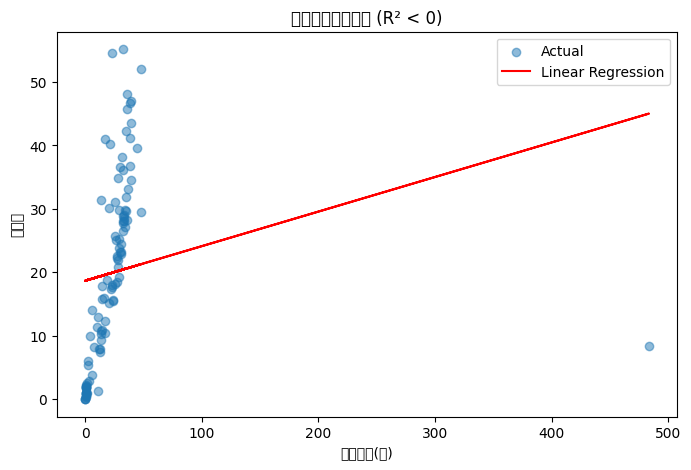

선택한 충전소: 앵봉산가족캠핑장


In [40]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# R²가 가장 낮은 충전소 선택
name = results_df[results_df["R2"] < 0].sort_values("R2").iloc[0]["충전소명"]

data = df_model[df_model["충전소명"] == name][
    ["충전시간_분", "충전량(kW)"]
].dropna().copy()

# 해당 충전소의 선형회귀 직선 계산
X = data[["충전시간_분"]]
y = data["충전량(kW)"]

model_check = LinearRegression()
model_check.fit(X, y)

data["예측값"] = model_check.predict(X)
data["절대오차"] = (data["충전량(kW)"] - data["예측값"]).abs()

# 실제 데이터와 직선 표시
plt.figure(figsize=(8, 5))
plt.scatter(data["충전시간_분"], y, alpha=0.5, label="Actual")
plt.plot(
    data["충전시간_분"],
    data["예측값"],
    color="red",
    label="Linear Regression"
)
plt.xlabel("충전시간(분)")
plt.ylabel("충전량")
plt.title(f"{name} (R² < 0)")
plt.legend()
plt.show()

print("선택한 충전소:", name)

In [41]:
# 직선에서 가장 멀리 떨어진 데이터 10개 확인
display(
    data.sort_values("절대오차", ascending=False)[
        ["충전시간_분", "충전량(kW)", "예측값", "절대오차"]
    ].head(10)
)

,충전시간_분,충전량(kW),예측값,절대오차
132727,483.116667,8.347,45.003089,36.656089
14057,32.866667,55.158,20.460686,34.697314
113128,22.850000,54.489,19.914693,34.574307
8308,47.700000,52.028,21.269227,30.758773
41829,35.633333,48.025,20.611492,27.413508
59280,39.250000,46.971,20.808631,26.162369
101878,38.816667,46.676,20.785011,25.890989
105280,35.500000,45.673,20.604224,25.068776
39757,39.166667,43.547,20.804088,22.742912
93808,34.883333,42.274,20.570611,21.703389


In [42]:
# 직선에서 가장 멀리 떨어진 데이터의 원본 기록 확인
row_index = 132727

display(
    df_model.loc[
        [row_index],
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전시간_분", "충전량(kW)"]
    ]
)

,충전소명,충전시작시간,충전종료시간,충전시간_분,충전량(kW)
132727,앵봉산가족캠핑장,2025-06-13 10:31:39,2025-06-13 18:34:46,483.116667,8.347


In [43]:
print("현재 df_model 데이터 개수:", len(df_model))

현재 df_model 데이터 개수: 215530


In [44]:
# 1. 이상치가 발견된 충전소 이름 지정
name = "앵봉산가족캠핑장"

# 2. 해당 충전소 데이터만 가져오기
station_data = df_model[
    df_model["충전소명"] == name
].copy()

# 3. 이상치 인덱스 132727만 제외
station_data_clean = station_data.drop(index=132727)

print("기존 데이터 개수:", len(station_data))
print("이상치 제외 후:", len(station_data_clean))

기존 데이터 개수: 102
이상치 제외 후: 101


In [45]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 입력 변수와 정답 설정
X = station_data_clean[["충전시간_분"]]
y = station_data_clean["충전량(kW)"]

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 선형회귀 모델 학습
model = LinearRegression()
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)

# 성능 평가
mae_after = mean_absolute_error(y_test, y_pred)
rmse_after = np.sqrt(mean_squared_error(y_test, y_pred))
r2_after = r2_score(y_test, y_pred)

print("=== 이상치 제외 후 성능 ===")
print("데이터 개수:", len(station_data_clean))
print("MAE:", round(mae_after, 4))
print("RMSE:", round(rmse_after, 4))
print("R²:", round(r2_after, 4))

=== 이상치 제외 후 성능 ===
데이터 개수: 101
MAE: 4.4693
RMSE: 5.8624
R²: 0.8673


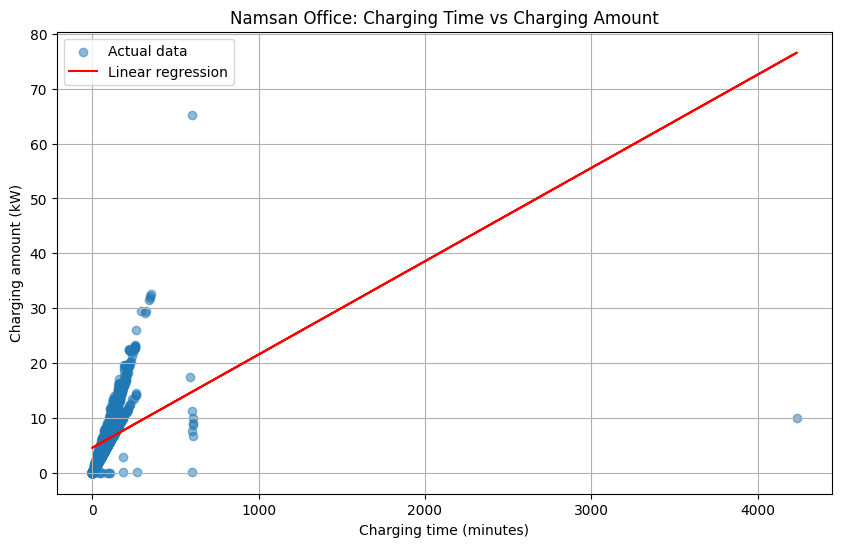

In [46]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 남산청사 데이터만 가져오기
station_data = df_model[
    df_model["충전소명"] == "남산청사"
][["충전시간_분", "충전량(kW)"]].dropna().copy()

# 모델 학습
X = station_data[["충전시간_분"]]
y = station_data["충전량(kW)"]

model = LinearRegression()
model.fit(X, y)

# 그래프 그리기
plt.figure(figsize=(10, 6))
plt.scatter(X["충전시간_분"], y, alpha=0.5, label="Actual data")

plt.plot(
    X["충전시간_분"],
    model.predict(X),
    color="red",
    label="Linear regression"
)

plt.xlabel("Charging time (minutes)")
plt.ylabel("Charging amount (kW)")
plt.title("Namsan Office: Charging Time vs Charging Amount")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
# 남산청사 데이터 불러오기
namsan_data = df_model[
    df_model["충전소명"] == "남산청사"
].copy()

print("남산청사 데이터 개수:", len(namsan_data))

display(namsan_data.head(20))

남산청사 데이터 개수: 1203


,충전소명,충전시작시간,충전종료시간,충전량(kW),충전시간_분
598,남산청사,2025-12-31 11:44:17,2025-12-31 12:45:52,3.211,61.583333
631,남산청사,2025-12-31 10:57:51,2025-12-31 12:39:44,7.072,101.883333
638,남산청사,2025-12-31 10:44:09,2025-12-31 11:44:01,6.378,59.866667
1125,남산청사,2025-12-30 18:16:45,2025-12-31 04:17:29,7.553,600.733333
1170,남산청사,2025-12-30 17:26:55,2025-12-30 17:28:40,0.074,1.750000
1198,남산청사,2025-12-30 16:57:46,2025-12-30 20:07:21,16.068,189.583333
1274,남산청사,2025-12-30 15:35:03,2025-12-30 16:57:26,4.596,82.383333
1359,남산청사,2025-12-30 13:54:40,2025-12-30 14:06:39,0.647,11.983333
1398,남산청사,2025-12-30 13:08:43,2025-12-30 13:42:11,1.835,33.466667
1486,남산청사,2025-12-30 11:26:49,2025-12-30 12:50:43,7.621,83.900000


In [48]:
# 남산청사 데이터 불러오기
namsan_data = df_model[
    df_model["충전소명"] == "남산청사"
][["충전시간_분", "충전량(kW)"]].dropna().copy()

from sklearn.linear_model import LinearRegression

X = namsan_data[["충전시간_분"]]
y = namsan_data["충전량(kW)"]

# 전체 데이터로 회귀선 생성 (이상치 탐색용)
model_check = LinearRegression()
model_check.fit(X, y)

# 예측값과 오차 계산
namsan_data["예측값"] = model_check.predict(X)
namsan_data["절대오차"] = (
    namsan_data["충전량(kW)"] - namsan_data["예측값"]
).abs()

# 회귀선에서 가장 멀리 떨어진 기록 20개
display(
    namsan_data.sort_values("절대오차", ascending=False).head(20)
)

,충전시간_분,충전량(kW),예측값,절대오차
136756,4233.700000,9.988,76.564637,66.576637
208453,600.716667,65.266,14.747786,50.518214
112689,353.716667,32.661,10.544970,22.116030
74368,349.433333,32.160,10.472087,21.687913
149748,346.066667,31.869,10.414802,21.454198
72941,342.516667,31.443,10.354397,21.088603
204782,291.666667,29.521,9.489161,20.031839
113255,321.516667,29.412,9.997073,19.414927
95334,317.866667,29.152,9.934966,19.217034
23300,265.550000,26.108,9.044774,17.063226


In [49]:
# 회귀선에서 멀리 떨어진 기록 4개 확인
check_indices = [136756, 208453, 112689, 74368]

display(
    df_model.loc[
        check_indices,
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전시간_분", "충전량(kW)"]
    ]
)

,충전소명,충전시작시간,충전종료시간,충전시간_분,충전량(kW)
136756,남산청사,2025-06-05 18:00:25,2025-06-08 16:34:07,4233.700000,9.988
208453,남산청사,2025-01-13 16:52:48,2025-01-14 02:53:31,600.716667,65.266
112689,남산청사,2025-07-17 16:03:43,2025-07-17 21:57:26,353.716667,32.661
74368,남산청사,2025-09-17 15:22:06,2025-09-17 21:11:32,349.433333,32.160


In [50]:
# 남산청사 데이터
namsan_data = df_model[
    df_model["충전소명"] == "남산청사"
].copy()

# 인덱스 확인
print("해당 인덱스 존재 여부:", 136756 in namsan_data.index)

# 첫 번째 기록만 제외
namsan_clean = namsan_data.drop(index=136756)

print("제외 전:", len(namsan_data))
print("제외 후:", len(namsan_clean))

해당 인덱스 존재 여부: True
제외 전: 1203
제외 후: 1202


In [51]:
# 앵봉산가족캠핑장 이상치 삭제
df_model = df_model.drop(index=132727, errors="ignore")

# 남산청사 이상치 삭제
df_model = df_model.drop(index=136756, errors="ignore")

In [52]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 개수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df = results_df.sort_values(
        "R2", ascending=False
    ).reset_index(drop=True)

    display(results_df)

print("모델을 실행한 충전소 수:", len(results_df))
print("R² 음수인 충전소 수:", (results_df["R2"] < 0).sum())

,충전소명,데이터 개수,MAE,RMSE,R2
0,사당종합체육관,200,0.421422,0.543663,0.992709
1,미아동 도봉세무서 앞 전기차 충전소,518,1.162947,1.878473,0.991163
2,봉화산역 공영주차장 전기차 충전소,756,1.571633,2.141916,0.986712
3,으뜸공원 공영주차장 전기차 충전소,439,1.456386,2.096946,0.984108
4,로봇과학관,87,0.941812,1.518333,0.981174
...,...,...,...,...,...
186,불암산공영주차장,196,10.761056,20.613299,-1.267559
187,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109
188,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
189,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554


모델을 실행한 충전소 수: 191
R² 음수인 충전소 수: 11


In [53]:
low_r2 = results_df[results_df["R2"] < 0].copy()

low_r2 = low_r2.sort_values("R2")

display(
    low_r2[
        ["충전소명", "데이터 개수", "MAE", "RMSE", "R2"]
    ]
)

print("R²가 0보다 작은 충전소 수:", len(low_r2))

,충전소명,데이터 개수,MAE,RMSE,R2
190,한마음공영주차장,933,11.105968,32.218113,-2.662466
189,마포유수지 공영주차장,1235,10.533730,29.523735,-2.468554
188,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.016124,30.178582,-2.463987
187,여의서로 노상공영주차장(가로등),1663,5.948548,21.672615,-1.903109
186,불암산공영주차장,196,10.761056,20.613299,-1.267559
185,노원구청,1046,10.413723,16.867754,-0.386079
184,어린이대공원 구의문 주차장 복합충전소,4065,11.816192,15.872260,-0.092692
183,교통공원길 공영주차장 전기차 충전소,1520,13.005449,19.245865,-0.021102
182,50+동부캠퍼스,490,13.489312,15.652546,-0.005852
181,월계복지문화센터,208,12.629780,16.116989,-0.004401


R²가 0보다 작은 충전소 수: 11


데이터 개수: 490


C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 52649 (\N{HANGUL SYLLABLE CUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gabin\AppData\Local\Temp\ipykernel_29384\3668307257.py:22: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing 

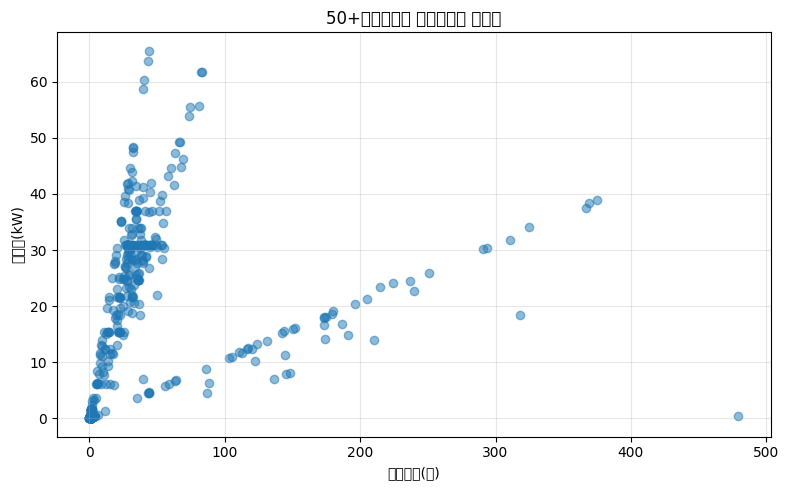

In [54]:
import matplotlib.pyplot as plt

name = "50+동부캠퍼스"

station_data = df_model[
    df_model["충전소명"].astype(str).str.strip() == name
].copy()

print("데이터 개수:", len(station_data))

plt.figure(figsize=(8, 5))
plt.scatter(
    station_data["충전시간_분"],
    station_data["충전량(kW)"],
    alpha=0.5
)

plt.xlabel("충전시간(분)")
plt.ylabel("충전량(kW)")
plt.title(f"{name} 충전시간과 충전량")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
name = "50+동부캠퍼스"

outliers = df_model[
    (df_model["충전소명"].astype(str).str.strip() == name) &
    (df_model["충전량(kW)"] <= 20) &
    (df_model["충전시간_분"] >= 300)
]

display(
    outliers[
        ["충전소명", "충전시작시간", "충전종료시간",
         "충전시간_분", "충전량(kW)"]
    ]
)

print("해당 데이터 인덱스:", outliers.index.tolist())

,충전소명,충전시작시간,충전종료시간,충전시간_분,충전량(kW)
139362,50+동부캠퍼스,2025-05-31 13:06:23,2025-05-31 18:24:35,318.200000,18.45
160337,50+동부캠퍼스,2025-04-18 10:58:26,2025-04-18 18:57:48,479.366667,0.38


해당 데이터 인덱스: [139362, 160337]


In [56]:
# 50+동부캠퍼스 이상치 2개 제거
df_model = df_model.drop(index=[139362, 160337], errors="ignore")

# 불암산공영주차장 삭제
df_model = df_model.drop(index=[47874], errors="ignore")

# 여의서로 노상공영주차장(가로등) 삭제
df_model = df_model.drop(index=[20577], errors="ignore")

# 노원구청 이상치 2개 제거
df_model = df_model.drop(index=[91016, 90663], errors="ignore")

## 한마음공영주차장 제거
df_model = df_model.drop(index=[211049], errors="ignore")

#  어린이대공원 구의문 주차장 복합충전소 이상치 2개 삭제
df_model = df_model.drop(index=[90474, 157271], errors="ignore")

# 교통공원길 충전시간 이상치 후보 제거
df_model = df_model.drop(index=[138608], errors="ignore")

# 월계복지문화센터 이상치 데이터 제거
df_model = df_model.drop(index=[30478], errors="ignore")

# 고척스카이돔 이상치 데이터 제거
df_model = df_model.drop(index=[143415], errors="ignore")

# 마포유수지 공영주차장 이상치 데이터 제거
df_model = df_model.drop(index=[193769], errors="ignore")



In [57]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

# 충전소별 선형회귀 재평가
for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    # 데이터가 너무 적거나 충전시간이 모두 같으면 제외
    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "실제 평균 충전량": y_test.mean(),
        "예측 평균 충전량": y_pred.mean(),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

# R²가 0보다 작은 충전소만 추출
negative_r2 = results_df[results_df["R2"] < 0].sort_values("R2")

display(negative_r2.round(4))



,충전소명,데이터 개수,MAE,RMSE,R2
190,한마음공영주차장,933,11.1060,32.2181,-2.6625
189,마포유수지 공영주차장,1235,10.5337,29.5237,-2.4686
188,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.0161,30.1786,-2.4640
187,여의서로 노상공영주차장(가로등),1663,5.9485,21.6726,-1.9031
186,불암산공영주차장,196,10.7611,20.6133,-1.2676
185,노원구청,1046,10.4137,16.8678,-0.3861
184,어린이대공원 구의문 주차장 복합충전소,4065,11.8162,15.8723,-0.0927
183,교통공원길 공영주차장 전기차 충전소,1520,13.0054,19.2459,-0.0211
182,50+동부캠퍼스,490,13.4893,15.6525,-0.0059
181,월계복지문화센터,208,12.6298,16.1170,-0.0044


In [58]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

# 충전소별 모델 재학습
for name, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

# 결과 갱신
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("R2").reset_index(drop=True)

# R²가 음수인 충전소만 출력
negative_r2 = results_df[results_df["R2"] > 0]

display(negative_r2.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
2,가산 공영주차장,420,6.8220,8.3047,0.0091
3,목동공영주차장,3260,12.8778,15.5745,0.0463
4,동작구청,2826,4.7018,5.7387,0.0516
5,송월동차고지,2935,12.1664,15.0812,0.0645
6,수서역 공영주차장 복합충전소,3924,11.3613,14.0996,0.0754
...,...,...,...,...,...
186,로봇과학관,87,0.9418,1.5183,0.9812
187,으뜸공원 공영주차장 전기차 충전소,439,1.4564,2.0969,0.9841
188,봉화산역 공영주차장 전기차 충전소,756,1.5716,2.1419,0.9867
189,미아동 도봉세무서 앞 전기차 충전소,518,1.1629,1.8785,0.9912


In [59]:
# 처음에 R²가 음수였던 13개 충전소
target_stations = [
    "앵봉산가족캠핑장",
    "남산청사",
    "한마음공영주차장",
    "마포유수지 공영주차장",
    "국립한글박물관 지하주차장(주차장 임시폐쇄)",
    "여의서로 노상공영주차장(가로등)",
    "불암산공영주차장",
    "노원구청",
    "어린이대공원 구의문 주차장 복합충전소",
    "교통공원길 공영주차장 전기차 충전소",
    "50+동부캠퍼스",
    "월계복지문화센터",
    "고척스카이돔"
]

# 최신 df_model로 해당 충전소들만 재평가
comparison_results = []

for name in target_stations:
    data = df_model[
        df_model["충전소명"].astype(str).str.strip() == name
    ][["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        print(f"데이터 부족 또는 충전시간 변동 없음: {name}")
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    comparison_results.append({
        "충전소명": name,
        "데이터 수": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,충전소명,데이터 수,MAE,RMSE,R2
0,앵봉산가족캠핑장,101,4.4693,5.8624,0.8673
1,남산청사,1202,1.7222,2.3300,0.7789
2,한마음공영주차장,932,8.8424,11.2735,0.5745
3,마포유수지 공영주차장,1234,8.7918,11.1287,0.5266
4,국립한글박물관 지하주차장(주차장 임시폐쇄),20,23.0161,30.1786,-2.4640
5,여의서로 노상공영주차장(가로등),1662,4.7477,6.4601,0.7562
6,불암산공영주차장,195,8.0501,9.6667,0.5071
7,노원구청,1044,8.8668,11.6598,0.4232
8,어린이대공원 구의문 주차장 복합충전소,4063,11.1306,13.7638,0.1414
9,교통공원길 공영주차장 전기차 충전소,1519,12.6783,16.0407,0.3347


In [60]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_stations = [
    "앵봉산가족캠핑장",
    "남산청사",
    "한마음공영주차장",
    "마포유수지 공영주차장",
    "국립한글박물관 지하주차장(주차장 임시폐쇄)",
    "여의서로 노상공영주차장(가로등)",
    "불암산공영주차장",
    "노원구청",
    "어린이대공원 구의문 주차장 복합충전소",
    "교통공원길 공영주차장 전기차 충전소",
    "50+동부캠퍼스",
    "월계복지문화센터",
    "고척스카이돔"
]

models = {
    "선형회귀": LinearRegression(),
    "의사결정나무": DecisionTreeRegressor(
        max_depth=5, random_state=42
    ),
    "랜덤 포레스트": RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    ),
    "그래디언트 부스팅": GradientBoostingRegressor(
        n_estimators=100, max_depth=3, random_state=42
    )
}

results = []

for name in target_stations:
    data = df_model[
        df_model["충전소명"].astype(str).str.strip() == name
    ][["충전시간_분", "충전량(kW)"]].dropna()

    if len(data) < 10 or data["충전시간_분"].nunique() < 2:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        results.append({
            "충전소명": name,
            "모델": model_name,
            "데이터 수": len(data),
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)
        })

model_comparison = pd.DataFrame(results)

display(
    model_comparison.sort_values(
        ["충전소명", "RMSE"]
    ).round(4)
)

,충전소명,모델,데이터 수,MAE,RMSE,R2
43,50+동부캠퍼스,그래디언트 부스팅,488,4.6669,9.4192,0.6482
42,50+동부캠퍼스,랜덤 포레스트,488,5.0735,10.0250,0.6015
41,50+동부캠퍼스,의사결정나무,488,4.8917,10.2446,0.5839
40,50+동부캠퍼스,선형회귀,488,13.3338,14.9821,0.1100
51,고척스카이돔,그래디언트 부스팅,1340,7.3665,10.1559,0.5013
49,고척스카이돔,의사결정나무,1340,7.4508,10.2452,0.4925
50,고척스카이돔,랜덤 포레스트,1340,7.4568,10.3059,0.4864
48,고척스카이돔,선형회귀,1340,11.5581,14.4376,-0.0079
39,교통공원길 공영주차장 전기차 충전소,그래디언트 부스팅,1519,9.4341,12.7426,0.5802
37,교통공원길 공영주차장 전기차 충전소,의사결정나무,1519,9.6856,13.0479,0.5598


In [6]:
from pathlib import Path

print("현재 작업 폴더:", Path.cwd())
print("\n현재 폴더의 파일 목록:")

for file in Path.cwd().iterdir():
    if file.is_file():
        print(file.name)

현재 작업 폴더: c:\test

현재 폴더의 파일 목록:
data.ipynb
model.ipynb
model_rf.ipynb
seoul_day_time.xlsx
test_data.csv
train_data.csv
Untitled-1.ipynb
Untitled-1.py
서울시 소유 전기차 충전소 정보.csv
서울시 소유 전기차충전기 일별 시간별 충전현황(2025년).xlsx


In [61]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=10,
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, max_depth=3, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=6,
        learning_rate=0.1, random_state=42,
        n_jobs=-1, verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=100, learning_rate=0.1,
        random_state=42, verbosity=-1, n_jobs=-1
    )
}

print("모델 개수:", len(models))
print(list(models.keys()))

모델 개수: 6
['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']


In [63]:
print("df_model 존재:", "df_model" in globals())
print("models 존재:", "models" in globals())
print("model_comparison_all 존재:", "model_comparison_all" in globals())

df_model 존재: True
models 존재: True
model_comparison_all 존재: False


In [64]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

all_results = []

for station, data in df_model.groupby("충전소명"):

    data = data[["충전시간_분", "충전량(kW)"]].copy()
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    data = data[
        (data["충전시간_분"] >= 0) &
        (data["충전량(kW)"] >= 0)
    ]

    if len(data) < 10:
        continue

    X = data[["충전시간_분"]]
    y = data["충전량(kW)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    for model_name, model in models.items():
        try:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            all_results.append({
                "충전소명": station,
                "모델": model_name,
                "데이터수": len(data),
                "MAE": mean_absolute_error(y_test, y_pred),
                "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
                "R2": r2_score(y_test, y_pred)
            })

        except Exception as e:
            print(f"{station} / {model_name} 오류: {e}")

model_comparison_all = pd.DataFrame(all_results)

print("평가 충전소 수:", model_comparison_all["충전소명"].nunique())
print("비교 모델 수:", model_comparison_all["모델"].nunique())
print("전체 평가 결과 수:", len(model_comparison_all))

display(model_comparison_all.head(20))

평가 충전소 수: 191
비교 모델 수: 6
전체 평가 결과 수: 1146


,충전소명,모델,데이터수,MAE,RMSE,R2
0,50+동부캠퍼스,Linear Regression,488,13.333840,14.982143,0.109986
1,50+동부캠퍼스,Decision Tree,488,4.891742,10.244636,0.583857
2,50+동부캠퍼스,Random Forest,488,5.073499,10.024973,0.601512
3,50+동부캠퍼스,Gradient Boosting,488,4.666922,9.419229,0.648213
4,50+동부캠퍼스,XGBoost,488,4.554873,8.320012,0.725529
5,50+동부캠퍼스,LightGBM,488,4.976631,8.988155,0.679675
6,AI 체육센터,Linear Regression,363,6.962897,10.084803,0.460306
7,AI 체육센터,Decision Tree,363,3.800836,6.947152,0.743890
8,AI 체육센터,Random Forest,363,3.952976,7.364162,0.712221
9,AI 체육센터,Gradient Boosting,363,3.874400,7.156672,0.728209


In [65]:
best_model_by_station = (
    model_comparison_all
    .sort_values(["충전소명", "RMSE"])
    .groupby("충전소명")
    .first()
    .reset_index()
)

display(best_model_by_station)

,충전소명,모델,데이터수,MAE,RMSE,R2
0,50+동부캠퍼스,XGBoost,488,4.554873,8.320012,0.725529
1,AI 체육센터,Decision Tree,363,3.800836,6.947152,0.743890
2,SK허브수 인근 거주자우선주차장 볼라드형 충전소,LightGBM,531,2.022667,3.065784,0.956210
3,가산 공영주차장,Decision Tree,420,3.478572,4.808866,0.667744
4,강남구 압구정 나들목 앞 가로등형 충전기,Linear Regression,4787,5.081378,7.090520,0.816276
...,...,...,...,...,...,...
186,홍제동 주영빌딩 앞 전기차 충전소(가로등),Linear Regression,844,7.728333,9.941209,0.344055
187,화곡본동주민센터,Gradient Boosting,733,6.647616,9.308130,0.613633
188,화창운수 앞 가로등형 충전소,Gradient Boosting,1314,6.026485,7.873468,0.649512
189,훈련원공원 노상공영주차장(가로등),Linear Regression,2559,4.604884,7.056969,0.658114


In [5]:
from pathlib import Path

folder = Path(r"C:\test\새 폴더")

if folder.exists() and folder.is_dir() and not any(folder.iterdir()):
    folder.rmdir()
    print("빈 폴더 삭제 완료")
else:
    print("폴더가 비어 있지 않거나 이미 없어.")

빈 폴더 삭제 완료


In [7]:
import json
from pathlib import Path

file_path = Path(r"C:\test\06_코드및노트북\data.ipynb")

with open(file_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"])
        if any(word in code for word in [
            "read_excel", "read_csv", "dropna",
            "fillna", "drop_duplicates", "merge",
            "groupby", "df =", "df["
        ]):
            print(f"\n--- 셀 {i + 1} ---")
            print(code)


--- 셀 2 ---
import pandas as pd

df = pd.read_excel("서울시 소유 전기차충전기 일별 시간별 충전현황(2025년).xlsx", header=3)


--- 셀 3 ---
# 각 열의 고유값 개수 확인 충전소별 데이터 개수 확인  
for col in df.columns:
    print(f"{col}: {df[col].nunique()}개")

--- 셀 5 ---
# 충전소별 데이터 개수
print(df["충전소명"].value_counts())

--- 셀 6 ---
# 중복을 제외한 충전소명 목록
print(df["충전소명"].unique())

# 충전소 개수
print("충전소 개수:", df["충전소명"].nunique())

--- 셀 7 ---
# 충전소명별로 데이터 그룹화
groups = df.groupby("충전소명")

# 충전소 개수 확인
print("충전소 개수:", df["충전소명"].nunique())

--- 셀 8 ---
# 첫 번째 충전소 이름 확인
name = df["충전소명"].unique()[0]
print(name)

# 해당 충전소 데이터만 보기
display(df[df["충전소명"] == name])

--- 셀 9 ---
for name, data in df.groupby("충전소명"):
    data.to_excel(f"{name}.xlsx", index=False)

--- 셀 11 ---
import pandas as pd

# 시작 시간과 종료 시간을 날짜/시간 형식으로 변환
df["충전시작시간"] = pd.to_datetime(df["충전시작시간"])
df["충전종료시간"] = pd.to_datetime(df["충전종료시간"])

# 종료 시간 - 시작 시간 → 분 단위로 변환
df["충전시간_분"] = (
    df["충전종료시간"] - df["충전시작시간"]
).dt.total_seconds() / 60

# 결과 확인
display(df.head())

-